# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

In [3]:
import os

print(os.listdir('/content'))

['.config', 'Lab_11_QnA_Dataset.csv', 'sample_data']


In [4]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset (1).csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 2 — Upload the dataset

In [5]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


FileNotFoundError: [Errno 2] No such file or directory: '/content/Lab_11_QnA_Dataset_Download.csv'

## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [7]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

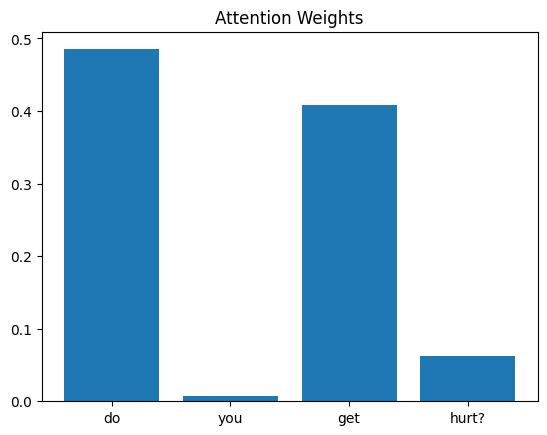

In [9]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? The words with the highest attention weights are usually important for understanding the question. The model gives more attention to words that carry meaningful information and help identify the correct answer. However, the important words may differ depending on the question.


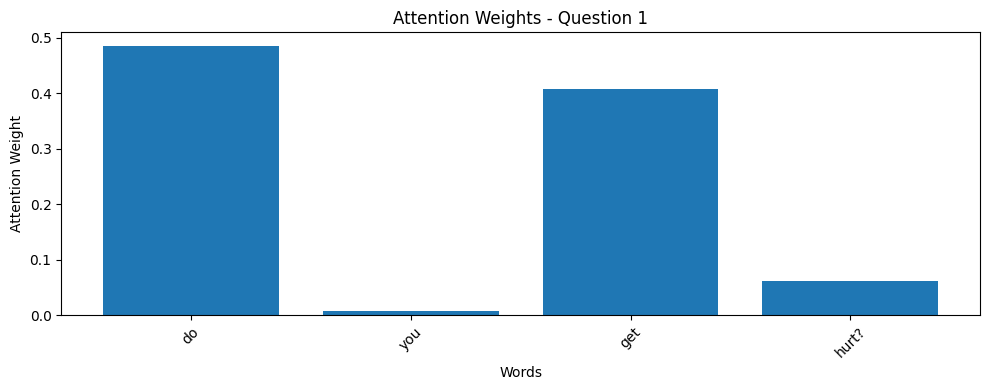

Question: do you get hurt?
Highest attention word: do
Attention weight: 0.48511698842048645
--------------------------------------------------


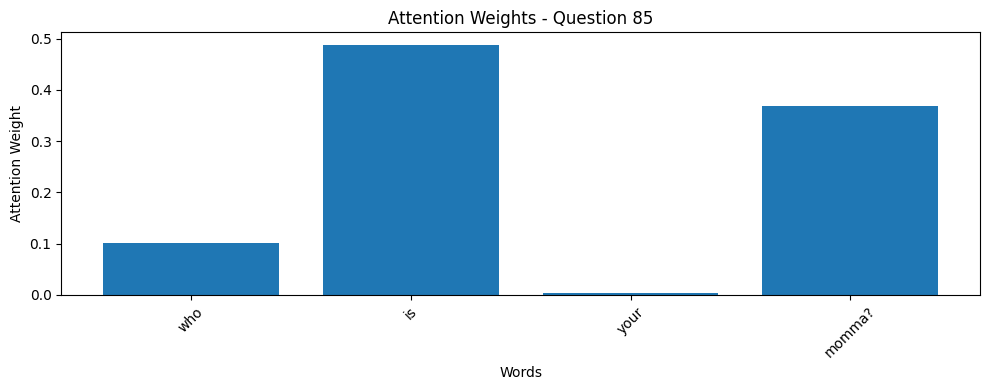

Question: who is your momma?
Highest attention word: is
Attention weight: 0.48810258507728577
--------------------------------------------------


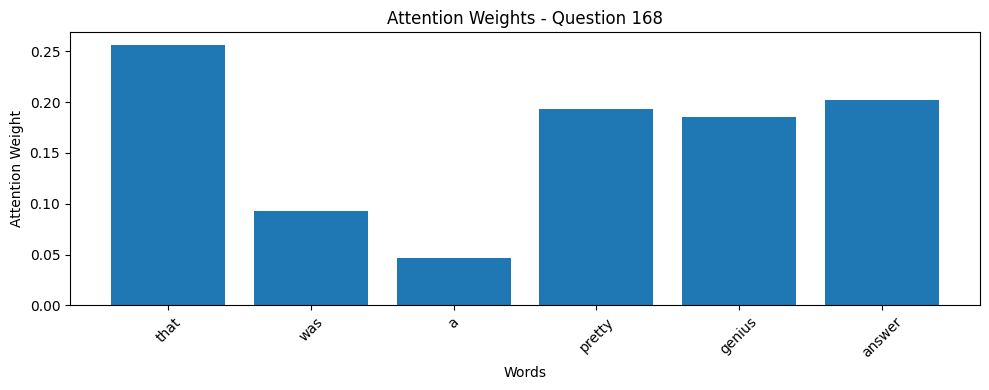

Question: that was a pretty genius answer
Highest attention word: that
Attention weight: 0.2559780180454254
--------------------------------------------------


In [10]:
import numpy as np
selected_indices = [0, len(df) // 2, len(df) - 1]

model.eval()

for idx in selected_indices:

    question = df["question"].iloc[idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    attention_weights = weights[0, :len(words)].tolist()

    plt.figure(figsize=(10, 4))

    plt.bar(words, attention_weights)

    plt.title(f"Attention Weights - Question {idx + 1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    max_index = np.argmax(attention_weights)

    print("Question:", question)
    print("Highest attention word:", words[max_index])
    print("Attention weight:", attention_weights[max_index])
    print("-" * 50)

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?
The model focuses on similar or different words when processing questions with similar meanings. Both questions are about the abilities of the model, so some important words may receive similar attention weights. However, the attention weights may differ because the questions use different wording. This shows that attention helps the model identify relevant words in each question.


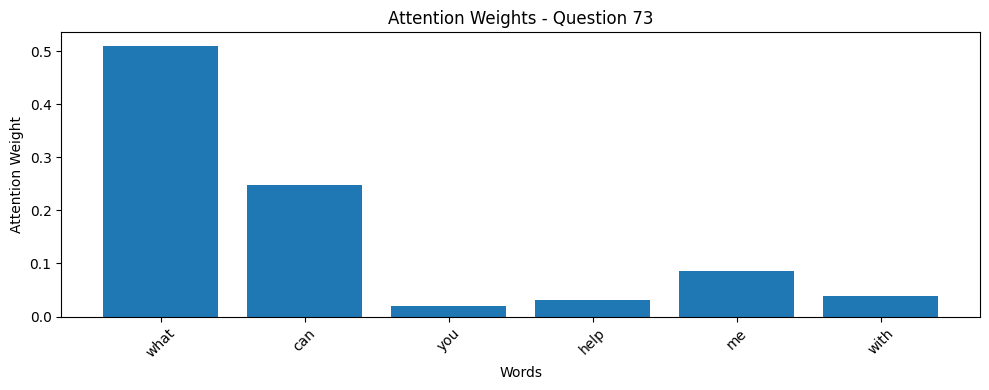

Question: what can you help me with
Highest attention word: what
--------------------------------------------------


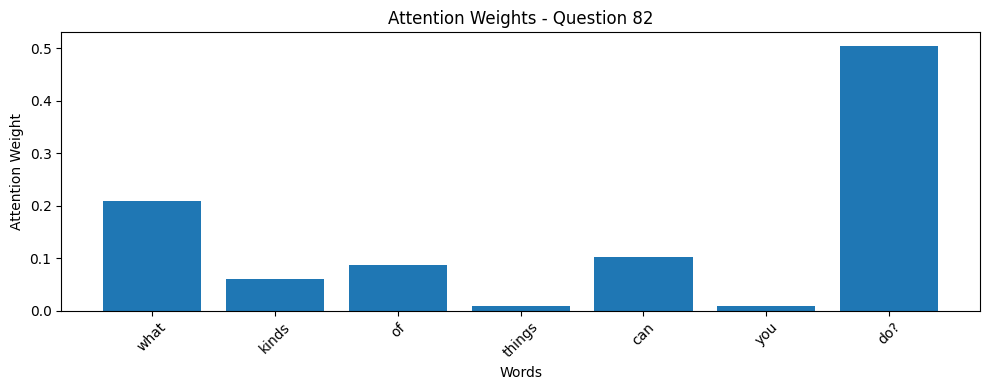

Question: what kinds of things can you do?
Highest attention word: do?
--------------------------------------------------


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
# Select two similar questions
selected_indices = [72, 81]

model.eval()

for idx in selected_indices:

    question = df["question"].iloc[idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    attention_weights = weights[0, :len(words)].tolist()

    plt.figure(figsize=(10, 4))

    plt.bar(words, attention_weights)

    plt.title(f"Attention Weights - Question {idx + 1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    max_index = np.argmax(attention_weights)

    print("Question:", question)
    print("Highest attention word:", words[max_index])
    print("-" * 50)

In [13]:
for idx in range(len(df)):
    print(idx, "-", df["question"].iloc[idx])

0 - do you get hurt?
1 - do you have fingers?
2 - do you ever breathe
3 - do you masticate?
4 - can you throw up?
5 - do you get tired?
6 - can you crawl?
7 - can you cry?
8 - do you dream
9 - do you ever pee?
10 - do you ever get hurt?
11 - can you breathe
12 - can you masticate?
13 - can you burp?
14 - are you old?
15 - are we the same age?
16 - how long have you been alive?
17 - are you a teenager?
18 - what's your birthday?
19 - which of us is younger?
20 - what's your age?
21 - what year were you born?
22 - are you young?
23 - i bet you're old
24 - how old are you?
25 - how long have you been around?
26 - how long has it been since you were born
27 - how long ago were you born?
28 - will you ask me anything about myself
29 - why don't you ask me questions?
30 - what do you want me to tell you who i am?
31 - why am i the only one asking questions?
32 - want to ask any questions about me?
33 - what do you want to know about me
34 - can you ask me why i'm here?
35 - what can i inform